# 이진 분류 실험 ⑥ — 계좌 이력 · 평소 대비 피처 추가 (account history)
1단계 피처 사다리의 네 번째 칸 (04 금액 분포는 효과가 없어 제외, 03 위에 쌓는다). 03 의 창 피처(1h/24h) 가 못 보는 **"이 계좌가 얼마나 오래·많이 썼나, 평소와 다른가"** 를 더한다. v10 채택 41종 중 정상 vs 무패턴 분리도가 높았던 묶음(`log_out_count` AUC 0.85, `day_ccy_rate_vs_prior` 0.83, `minute_sender_vs_prior_hour` 교란 시 무패턴 R −4.4pt) 을 우리 규칙(과거만) 으로 다시 정의한 것.

| 피처 | 뜻 | v10 대응 |
|---|---|---|
| `src_hist_out` / `dst_hist_in` | 전날까지 누적 송금 / 수취 건수 | `log_out_count` / `log_in_count` |
| `src_hist_uniq_out` / `dst_hist_uniq_in` | 전날까지 누적 서로 다른 상대 수 | `log_out_neighbors` / `log_in_neighbors` |
| `src_active_days` / `dst_active_days` | 전날까지 활동한 날짜 수 | `log_active_days` |
| `src_rate_vs_prior` / `dst_rate_vs_prior` | 최근 24h 건수 vs 과거 일평균 건수: ln(1+24h) − ln(1+누적/활동일). 이력 없으면 0 | `day_ccy_rate_vs_prior` (과거만 쓰는 판) |
| `src_minute_burst` / `dst_minute_burst` | 같은 분 집중도: ln(1+60·같은 분 건수) − ln(1+직전 60분 건수) | `minute_sender/receiver_vs_prior_hour` |
| `src_gap_minutes` / `dst_gap_minutes` | 계좌의 직전 거래까지 log(2+분), 없으면 0 | `sender/receiver_gap_minutes` |
| (선택) `src_amount_seen` / `dst_amount_seen` | 이 계좌가 전날까지 같은 금액을 처리한 적 있나 (0/1) | `prior_ccy_amount_seen` |

전부 ln. 누적·amount_seen 은 **전날까지**(일 단위 ASOF, reverse_history 와 같은 꼴), 창·간격은 **거래 시각 기준 과거, 같은 분 제외**. 예외는 `minute_burst` 하나 — 분 단위 데이터라 같은 분 안의 순서가 없어 같은 분 건수 전체를 쓴다(v10 과 동일, 일 마감 서비스에선 문제 없음).

**가설**: 무패턴 세탁(UNMATCHED, 양성의 41%) 은 이력이 짧은 계좌·평소보다 갑자기 활발한 계좌에서 나온다 → UNMATCHED 의 argmax recall(03: 0.013) 과 평균 점수(0.063), 1% 컷(0.431) 이 오르면 성공. 매칭 패턴은 03 수준 유지.
**amount_seen 은 꺼 두고 시작** (`USE_AMOUNT_SEEN = False`): v10 에서 가장 강한 무패턴 신호(ACH AUC 0.89) 였지만 AMLworld 정상 거래의 금액 반복 규칙에 기댄 것이라 SAML-D 에서 붕괴. parquet 엔 계산해 두고, 켠 조건은 두 번째 런으로.

**메모리**: 03 파이프라인 + 피처 행렬을 학습 전에 GPU 로 (`store.features_to_gpu`). 18 + 12 = 30열 → GPU 10.8GB, 학습 9.5GB → V100 32GB 안 (다른 프로세스 11GB 가 남아 있으면 빠듯 — 학습 CUDA OOM 이면 `batch_size=1024, iter_per_epoch=512` 로). 호스트는 memmap 을 안 읽어 스래싱 없음. 추론 배치 2048.

**누수 규칙**: 거래 시각 기준 과거만(같은 분 제외; minute_burst 만 같은 분 포함), z-norm 은 학습 구간 통계. 공통 코드 `bc_lib.py`

# 공통 부분 (작업 준비, 데이터 준비)

## 0. 작업 준비

In [1]:
import sys, json, time, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

sys.path.append(str(Path.cwd()))
import bc_lib as B
L = B.L

In [2]:
# ---- 실험 설정 ------------------------------------------------------------
RUN_NAME = 'account_history'      # results/<DATASET>/account_history/
PREV_RUN = 'account_activity'     # 비교 기준 (03). 04 는 제외
cfg = B.Config(dataset='HI-Large', smoke=False, eval_batch_size=2048)
B.seed_all(cfg.seed)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT_DIR = cfg.out_dir(RUN_NAME)
USE_AMOUNT_SEEN = False           # True 면 amount_seen 2열 포함 (두 번째 런)

# 앞 단계 피처 (02·03 parquet 재사용) + 이번 단계 피처
PAIR_FEATURES = ['pair_prior_count', 'pair_gap_minutes', 'pair_count_1h', 'reverse_history_count']
PAIR_PATH = cfg.feat_dir / 'pair_history.parquet'
ACT_FEATURES = ['src_out_1h', 'src_out_1d', 'src_uniq_dst_1d', 'src_out_amt_1d', 'dst_in_1h', 'dst_in_1d', 'dst_uniq_src_1d', 'dst_in_amt_1d']
ACT_PATH = cfg.feat_dir / 'account_activity.parquet'
STAGE_FEATURES = ['src_hist_out', 'src_hist_uniq_out', 'src_active_days', 'src_rate_vs_prior', 'src_minute_burst', 'src_gap_minutes',
                  'dst_hist_in', 'dst_hist_uniq_in', 'dst_active_days', 'dst_rate_vs_prior', 'dst_minute_burst', 'dst_gap_minutes']
OPT_FEATURES = ['src_amount_seen', 'dst_amount_seen']
if USE_AMOUNT_SEEN:
    STAGE_FEATURES = STAGE_FEATURES + OPT_FEATURES; RUN_NAME = RUN_NAME + '_amtseen'; OUT_DIR = cfg.out_dir(RUN_NAME)
STAGE_PATH = cfg.feat_dir / 'account_history.parquet'
PREV_FEATURES = PAIR_FEATURES + ACT_FEATURES
GNN_EDGE_FEATURES = B.BASIC_EDGE_FEATURES + B.PORT_FEATURES + PREV_FEATURES + STAGE_FEATURES   # FEAT16 열 순서 (30). port 는 4,5 번
TREE_FEATURES = B.BASIC_EDGE_FEATURES + PREV_FEATURES + STAGE_FEATURES                         # 트리는 port 없이 (28)
for p_ in (PAIR_PATH, ACT_PATH):
    assert p_.exists(), f'앞 단계 parquet 이 없다: {p_}'
DEVICE, OUT_DIR, len(GNN_EDGE_FEATURES), len(TREE_FEATURES)

(device(type='cuda'),
 PosixPath('/workspace/money_laundry_ai_/code/binary_classification/results/HI-Large/account_history'),
 30,
 28)

In [3]:
cfg

Config(dataset='HI-Large', smoke=False, val_neg_rate=0.02, scale_pos_weight=6, tree_rounds=500, tree_early_stop=20, num_neighbors=[100, 100], batch_size=2048, eval_batch_size=2048, iter_per_epoch=256, epochs=400, eval_period=4, patience=8, class_weight=[1.0, 6.27], n_hidden=66, n_gnn_layers=2, lr=0.006, dropout=0.01, final_dropout=0.1, num_workers=0, seed=42)

## 1. 이번 단계 피처 계산 — 계좌 이력 · 평소 대비 (tx 를 올리기 **전에**)
03 과 같은 이유: DuckDB 창 함수(12GB) 와 tx 를 동시에 올리면 한도를 넘는다. 한 번 만들면 이 절은 바로 지나간다

- (a) **일 단위 계좌 상태**: (계좌, 날짜) 별 건수 → 누적 건수·누적 상대 수(그 쌍의 첫 거래일에 1)·활동 일수를 날짜순 누적. 송신 역할·수신 역할 따로. `reverse_history` 와 같은 꼴로 **ASOF (전날까지)** 붙인다 — 행 수가 (계좌 × 활동일) 이라 1.8억 조인이 아님
- (b) **창 함수** (03 과 같은 꼴): 같은 분 건수(`PARTITION BY src, ts`), 직전 60분·24h 건수, 직전 거래 시각(`UNBOUNDED … 1 minute PRECEDING`), 같은 금액의 첫 거래일(`PARTITION BY src, received`). src 한 번, dst 한 번
- (c) ln 변환·조합 후 저장 (edge_id 순). `rate_vs_prior` = ln(1+24h 건수) − ln(1+누적/활동일), `minute_burst` = ln(1+60·같은 분) − ln(1+직전 60분), `amount_seen` = 첫 거래일 < 대상일
- 결과는 `features_bc/account_history.parquet` (14열, amount_seen 포함)

In [4]:
con = L.connect(threads=8, memory='12GB')
currency_codes, format_codes = B.code_tables(con, cfg)
PORTS_PATH = B.ensure_ports(con, cfg)               # 있으면 건너뜀

In [6]:
# 이전 실행이 COPY 도중 죽었으면 불완전한 parquet 이 남아 있을 수 있다 → 행 수가 tx 와 다르면 지우고 다시 만든다
if STAGE_PATH.exists():
    n_stage = con.execute(f"SELECT count(*) FROM read_parquet({L.q(STAGE_PATH)})").fetchone()[0]
    n_tx = con.execute(f"SELECT count(*) FROM read_parquet({L.q(cfg.tx_path)})").fetchone()[0]
    if n_stage != n_tx:
        print(f'불완전한 {STAGE_PATH.name} ({n_stage:,} / {n_tx:,} 행) → 삭제 후 재생성'); STAGE_PATH.unlink()
if not STAGE_PATH.exists():
    t0 = time.time()
    con.execute(f"""
        CREATE OR REPLACE TABLE tx_min AS
        SELECT edge_id, src, dst, ts, day, received FROM read_parquet({L.q(cfg.tx_path)})""")
    # (a) 일 단위 계좌 상태 — 송신 역할 / 수신 역할. 그 다음 (계좌, 날짜) 마다 전날까지의 상태를 ASOF 로
    for role, acct_col, other_col in [('out', 'src', 'dst'), ('in', 'dst', 'src')]:
        con.execute(f"""
            CREATE OR REPLACE TABLE {role}_state AS
            WITH d AS (SELECT {acct_col} AS acct, day, count(*) AS n FROM tx_min GROUP BY 1, 2),
                 p AS (SELECT {acct_col} AS acct, day, count(*) AS new_partners
                       FROM (SELECT {acct_col}, {other_col}, min(day) AS day FROM tx_min GROUP BY 1, 2) GROUP BY 1, 2)
            SELECT d.acct, d.day, sum(d.n) OVER w AS cum_cnt, sum(coalesce(p.new_partners, 0)) OVER w AS cum_uniq, count(*) OVER w AS active_days
            FROM d LEFT JOIN p USING (acct, day)
            WINDOW w AS (PARTITION BY d.acct ORDER BY d.day ROWS UNBOUNDED PRECEDING)""")
        con.execute(f"""
            CREATE OR REPLACE TABLE {acct_col}_hist AS
            SELECT t.{acct_col} AS acct, t.day, s.cum_cnt, s.cum_uniq, s.active_days
            FROM (SELECT DISTINCT {acct_col}, day FROM tx_min) t
            ASOF LEFT JOIN {role}_state s ON t.{acct_col} = s.acct AND t.day > s.day""")
        con.execute(f"DROP TABLE {role}_state")
        print(f'  {acct_col}_hist {time.time()-t0:.0f}s')
    # (b)+(c) 한쪽(src/dst)씩: 창 함수 → 바로 ln 변환·조합해 피처 테이블로. 1.8억 행 테이블을 넷 동시에 조인하면 12GB 초과 (OOM) 라 한쪽씩
    for a, hist_name, uniq_name in [('src', 'hist_out', 'hist_uniq_out'), ('dst', 'hist_in', 'hist_uniq_in')]:
        con.execute(f"""
            CREATE OR REPLACE TABLE {a}_win AS
            SELECT edge_id,
                   count(*) OVER (PARTITION BY {a}, ts) - 1          AS same_min,
                   count(*) OVER w1h                                 AS n_1h,
                   count(*) OVER w1d                                 AS n_1d,
                   max(ts)  OVER wall                                AS last_ts,
                   min(day) OVER (PARTITION BY {a}, received)        AS amt_first_day
            FROM tx_min
            WINDOW w1h  AS (PARTITION BY {a} ORDER BY ts RANGE BETWEEN INTERVAL '60 minutes' PRECEDING AND INTERVAL '1 minute' PRECEDING),
                   w1d  AS (PARTITION BY {a} ORDER BY ts RANGE BETWEEN INTERVAL '24 hours'  PRECEDING AND INTERVAL '1 minute' PRECEDING),
                   wall AS (PARTITION BY {a} ORDER BY ts RANGE BETWEEN UNBOUNDED PRECEDING AND INTERVAL '1 minute' PRECEDING)""")
        print(f'  {a}_win {time.time()-t0:.0f}s')
        con.execute(f"""
            CREATE OR REPLACE TABLE {a}_feat AS
            SELECT t.edge_id,
                   ln(1 + coalesce(h.cum_cnt, 0))::FLOAT                                                          AS {a}_{hist_name},
                   ln(1 + coalesce(h.cum_uniq, 0))::FLOAT                                                         AS {a}_{uniq_name},
                   ln(1 + coalesce(h.active_days, 0))::FLOAT                                                      AS {a}_active_days,
                   (CASE WHEN h.active_days IS NULL THEN 0 ELSE ln(1 + w.n_1d) - ln(1 + h.cum_cnt / h.active_days) END)::FLOAT AS {a}_rate_vs_prior,
                   (ln(1 + 60 * w.same_min) - ln(1 + w.n_1h))::FLOAT                                               AS {a}_minute_burst,
                   (CASE WHEN w.last_ts IS NULL THEN 0 ELSE ln(2 + date_diff('minute', w.last_ts, t.ts)) END)::FLOAT AS {a}_gap_minutes,
                   (CASE WHEN w.amt_first_day < t.day THEN 1 ELSE 0 END)::FLOAT                                      AS {a}_amount_seen
            FROM tx_min t JOIN {a}_win w USING (edge_id) JOIN {a}_hist h ON t.{a} = h.acct AND t.day = h.day""")
        con.execute(f"DROP TABLE {a}_win; DROP TABLE {a}_hist")
        print(f'  {a}_feat {time.time()-t0:.0f}s')
    # (d) 두 쪽을 edge_id 로 조인해 저장 (edge_id 순)
    con.execute(f"""
        COPY (SELECT s.*, d.* EXCLUDE (edge_id) FROM src_feat s JOIN dst_feat d USING (edge_id) ORDER BY s.edge_id)
        TO {L.q(STAGE_PATH)} (FORMAT PARQUET, COMPRESSION ZSTD)""")
    con.execute("DROP TABLE src_feat; DROP TABLE dst_feat; DROP TABLE tx_min")
    print(f'{STAGE_PATH.name} 생성 {time.time()-t0:.0f}s')
con.execute(f"SELECT count(*), {', '.join(f'avg({c}) AS avg_{c}' for c in STAGE_FEATURES + OPT_FEATURES)} FROM read_parquet({L.q(STAGE_PATH)})").df().T

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  src_hist 68s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (9 outputs left out)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

account_history.parquet 생성 993s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,0
count_star(),1.797021e+08
avg_src_hist_out,5.496731e+00
avg_src_hist_uniq_out,2.466061e+00
avg_src_active_days,3.320154e+00
avg_src_rate_vs_prior,-2.340780e-01
avg_src_minute_burst,-1.237269e-01
avg_src_gap_minutes,4.170088e+00
avg_dst_hist_in,4.318923e+00
avg_dst_hist_uniq_in,1.566588e+00
avg_dst_active_days,3.311955e+00


In [7]:
# 창 동작 확인 — 하루에 거래 8건쯤 보낸 계좌 하나의 송금 타임라인. hist_out 은 날짜가 바뀔 때만 늘고(전날까지), rate 는 24h 건수 vs 평균, burst 는 같은 분에 몰릴 때만 양수인지
# 주의: 1.8억 건끼리 조인하지 않는다 → 그 계좌의 edge_id 만 골라 피처 parquet 에서 읽는다
acct = con.execute(f"SELECT src FROM read_parquet({L.q(cfg.tx_path)}) GROUP BY src, day ORDER BY abs(count(*) - 8), src LIMIT 1").fetchone()[0]
ids = con.execute(f"SELECT edge_id, ts, dst, received FROM read_parquet({L.q(cfg.tx_path)}) WHERE src = {acct} ORDER BY ts LIMIT 40").df()
feat = con.execute(f"SELECT edge_id, src_hist_out, src_hist_uniq_out, src_active_days, src_rate_vs_prior, src_minute_burst, src_gap_minutes, src_amount_seen FROM read_parquet({L.q(STAGE_PATH)}) WHERE edge_id IN ({', '.join(map(str, ids.edge_id))})").df()
tl = ids.merge(feat, on='edge_id').sort_values('ts')
for c in ['src_hist_out', 'src_hist_uniq_out', 'src_active_days']:
    tl[c.replace('src_', '') + ' (수)'] = np.expm1(tl[c]).round(0).astype(int)      # ln(1+x) 를 되돌려
tl

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,edge_id,ts,dst,received,src_hist_out,src_hist_uniq_out,src_active_days,src_rate_vs_prior,src_minute_burst,src_gap_minutes,src_amount_seen,hist_out (수),hist_uniq_out (수),active_days (수)
0,130498,2022-08-01 00:03:00,0,11.21,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0,0,0
1,1736297,2022-08-01 03:39:00,86029,521.90,0.000000,0.000000,0.000000,0.000000,0.000000,5.384495,0.0,0,0,0
2,1760854,2022-08-01 03:50:00,86029,564.35,0.000000,0.000000,0.000000,0.000000,-0.693147,2.564949,0.0,0,0,0
3,2130513,2022-08-01 06:36:00,65675,1847.03,0.000000,0.000000,0.000000,0.000000,0.000000,5.123964,0.0,0,0,0
4,2179612,2022-08-01 06:58:00,65675,2285.52,0.000000,0.000000,0.000000,0.000000,-0.693147,3.178054,0.0,0,0,0
5,3559332,2022-08-01 17:15:00,0,1259.35,0.000000,0.000000,0.000000,0.000000,0.000000,6.428105,0.0,0,0,0
6,3785254,2022-08-01 18:56:00,29873,1127.66,0.000000,0.000000,0.000000,0.000000,0.000000,4.634729,0.0,0,0,0
7,4269502,2022-08-01 22:32:00,0,65.15,0.000000,0.000000,0.000000,0.000000,0.000000,5.384495,0.0,0,0,0
8,4296345,2022-08-01 22:44:00,0,579.25,0.000000,0.000000,0.000000,0.000000,-0.693147,2.639057,0.0,0,0,0
9,4750022,2022-08-02 02:52:00,29873,1127.66,2.302585,1.609438,0.693147,-0.105361,0.000000,5.521461,1.0,9,4,1


## 2. 데이터 준비 — 거래 전체 + port + 앞 단계 피처(02·03) + 이번 피처
전부 edge_id 순 parquet 이라 조인 없이 열만 붙인다 (`attach_parquet`, float16)

In [8]:
con.close(); con = L.connect(threads=8, memory='3GB')      # 창 함수가 잡아 둔 DuckDB 버퍼 반납. 이후 쿼리는 작아서 3GB 면 충분
con.register('currency_codes', currency_codes); con.register('format_codes', format_codes)   # 코드표는 연결마다 다시 등록
tx = B.load_tx_lowmem(con, cfg, port_path=PORTS_PATH)                      # 기본 9열 + port 2열 — parquet 에서 열 하나씩
B.trim('(tx 기본+port 적재 후)')
tx = B.attach_parquet(tx, PAIR_PATH, PAIR_FEATURES, dtype=np.float16)     # 02
tx = B.attach_parquet(tx, ACT_PATH, ACT_FEATURES, dtype=np.float16)       # 03
tx = B.attach_parquet(tx, STAGE_PATH, STAGE_FEATURES, dtype=np.float16)   # 이번 피처 (amount_seen 은 USE_AMOUNT_SEEN 일 때만)
B.trim(f'(피처 {len(PREV_FEATURES) + len(STAGE_FEATURES)}열 붙인 후)'); tx.shape

RSS 9.6 GB (tx 기본+port 적재 후)
RSS 18.4 GB (피처 24열 붙인 후)


(179702079, 35)

In [9]:
tx.head()

/usr/local/lib/python3.12/dist-packages/pandas/io/formats/format.py:1466: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,edge_id,src,dst,day,timestamp,amount_received,received_currency,payment_format,y,in_port,...,src_active_days,src_rate_vs_prior,src_minute_burst,src_gap_minutes,dst_hist_in,dst_hist_uniq_in,dst_active_days,dst_rate_vs_prior,dst_minute_burst,dst_gap_minutes
0,1,3,3,2022-08-01,0.0,19.180000,12,5,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0
1,2,25,78803,2022-08-01,0.0,17955.109375,12,3,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.109375,0.0
2,3,31,86028,2022-08-01,0.0,1199.829956,12,2,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0
3,4,39,269980,2022-08-01,0.0,148565.453125,12,6,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0
4,5,50,29866,2022-08-01,0.0,227247.421875,12,3,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0


In [10]:
tx[STAGE_FEATURES].describe().T

/usr/local/lib/python3.12/dist-packages/pandas/core/nanops.py:1524: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:49: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
/usr/local/lib/python3.12/dist-packages/pandas/core/nanops.py:725: RuntimeWarning: invalid value encountered in scalar divide
  the_mean = the_sum / count if count > 0 else np.nan
/usr/local/lib/python3.12/dist-packages/pandas/core/nanops.py:1524: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:49: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
/usr/local/lib/python3.12/dist-packages/pandas/core/nanops.py:725: RuntimeWarning: invalid value encountered in scalar divide
  the_mean = the_sum / count if count > 0 else np.nan
/usr/local

,count,mean,std,min,25%,50%,75%,max
src_hist_out,179702079.0,NaN,0.0,0.000000,4.109375,5.175781,6.046875,15.640625
src_hist_uniq_out,179702079.0,NaN,0.0,0.000000,1.386719,1.791992,2.197266,10.929688
src_active_days,179702079.0,NaN,0.0,0.000000,2.773438,3.689453,4.175781,4.820312
src_rate_vs_prior,179702079.0,NaN,0.0,-3.500000,-0.542480,-0.081299,0.124023,2.251953
src_minute_burst,179702079.0,NaN,0.0,-8.242188,-0.693359,0.000000,0.000000,9.828125
src_gap_minutes,179702079.0,NaN,0.0,0.000000,1.946289,3.044922,6.613281,12.023438
dst_hist_in,179702079.0,NaN,0.0,0.000000,3.761719,4.671875,5.218750,10.296875
dst_hist_uniq_in,179702079.0,NaN,0.0,0.000000,1.386719,1.609375,1.791992,7.742188
dst_active_days,179702079.0,NaN,0.0,0.000000,2.773438,3.664062,4.109375,4.820312
dst_rate_vs_prior,179702079.0,NaN,0.0,-7.589844,-0.681641,-0.154175,0.126709,4.492188


In [11]:
# 라벨별 평균 — 세탁 거래에서 값이 다른가 (피처가 신호를 갖는지 미리 확인). pandas groupby 는 열 단위라 가볍다
tx.groupby('y')[STAGE_FEATURES].mean().T.rename(columns={0: 'normal', 1: 'laundering'})

y,normal,laundering
src_hist_out,5.498032,4.436062
src_hist_uniq_out,2.466184,2.490170
src_active_days,3.320865,2.732481
src_rate_vs_prior,-0.233704,-0.542386
src_minute_burst,-0.126006,1.583084
src_gap_minutes,4.166637,6.973992
dst_hist_in,4.319902,3.517966
dst_hist_uniq_in,1.566691,1.650215
dst_active_days,3.312551,2.829490
dst_rate_vs_prior,-0.292246,-0.409934


## 3. z-norm (학습 구간 통계) + 표본

In [12]:
in_train = B.window_mask(tx, cfg.train_window)
FEAT_PATH = cfg.feat_dir / f'feat16_{RUN_NAME}.npy'                       # z-norm 행렬을 디스크 memmap 으로 (30열 10.8GB 가 RSS 에서 빠짐)
feat_z, znorm_table = B.znorm_features(tx, GNN_EDGE_FEATURES, in_train, out_path=FEAT_PATH)   # tx 에서 피처 열은 떨어짐
B.trim('(z-norm 후)'); znorm_table

RSS 6.3 GB (z-norm 후)


,feature,mean(train),std(train)
0,timestamp,3.036519e+06,1.403026e+06
1,amount_received,5.573174e+06,1.804616e+09
2,received_currency,8.450158e+00,4.231340e+00
3,payment_format,2.946519e+00,1.430707e+00
4,in_port,1.691504e+00,2.026216e+01
5,out_port,1.258211e+03,5.523149e+03
6,pair_prior_count,3.619805e+00,1.249467e+00
7,pair_gap_minutes,4.934153e+00,3.020589e+00
8,pair_count_1h,3.837265e-01,4.403188e-01
9,reverse_history_count,1.201983e-01,5.942292e-01


In [13]:
print(f"데이터 기간 {tx['day'].min().date()} ~ {tx['day'].max().date()}")
for name, w in [('train', cfg.train_window), ('val', cfg.val_window), ('test', cfg.test_window)]:
    m = B.window_mask(tx, w); assert m.sum() > 0, f'{name} 구간 {w} 에 거래가 없음'
    print(f'{name:5s} {w}  거래 {m.sum():>12,}  세탁 {tx.loc[m, "y"].sum():>8,}  비율 {tx.loc[m, "y"].mean()*100:.3f}%')

데이터 기간 2022-08-01 ~ 2023-01-12
train 2022-08-08:2022-10-02  거래  102,336,629  세탁  110,671  비율 0.108%
val   2022-10-03:2022-10-16  거래   24,413,046  세탁   33,795  비율 0.138%
test  2022-10-17:2022-10-30  거래   26,808,230  세탁   34,460  비율 0.129%


In [14]:
val_df = B.val_sample(con, cfg.val_window, cfg.val_neg_rate)        # 검증: 가중 표본 (05 공유)
test_df = B.test_full(con, cfg.test_window)                         # 테스트: 구간 전체
in_degree = B.recipient_indegree(con, cfg)                           # 분석용
con.close()

all_edge_ids = tx['edge_id'].to_numpy()
val_idx = B.rows_of(all_edge_ids, val_df['edge_id'].to_numpy()); test_idx = B.rows_of(all_edge_ids, test_df['edge_id'].to_numpy())
assert (tx['y'].to_numpy()[val_idx] == val_df['y'].to_numpy()).all()
del all_edge_ids
val_df.shape, test_df.shape

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

((521382, 7), (26808230, 5))

# 트리 모델 (기본 4 + pair 4 + 활동 8 + 이번 피처 12)

## 4. LightGBM / XGBoost

In [15]:
results = {}
tree_cols = [GNN_EDGE_FEATURES.index(c) for c in TREE_FEATURES]
train_mask = in_train; train_rows = np.flatnonzero(train_mask)
# X_train(1억 × 28 float32 = 11.5GB) 을 만들지 않는다 — LightGBM Sequence / XGBoost DataIter 로 memmap 을 묶음으로 읽어 bin 만 남긴다 (04 와 같음)
y_train = tx['y'].to_numpy()[train_mask]
X_val, y_val, w_val = B.rows_matrix(feat_z, val_idx, tree_cols), val_df['y'].to_numpy(), val_df['w'].to_numpy()
test_pred = lambda m: B.predict_rows(m, feat_z, test_idx, tree_cols)     # 테스트 행렬도 안 만들고 묶음 예측
B.trim('(트리 입력 준비 후)'); len(train_rows), X_val.shape

RSS 8.8 GB (트리 입력 준비 후)


(102336629, (521382, 28))

In [16]:
lgb_model, xgb_model = B.train_trees_lowmem(feat_z, train_rows, tree_cols, y_train, X_val, y_val, w_val, test_pred, val_df, test_df, cfg, results)
pd.DataFrame({'feature': TREE_FEATURES, 'lightgbm_gain': lgb_model.booster_.feature_importance('gain'),
              'xgboost_gain': [xgb_model.get_booster().get_score(importance_type='gain').get(f'f{i}', 0.0) for i in range(len(TREE_FEATURES))]})

[07:49:25] lightgbm val AP 0.6460  (best_it 381)
RSS 8.9 GB (lightgbm 후)
[08:30:35] xgboost  val AP 0.6505  (best_it 437)
RSS 9.1 GB (xgboost 후)


,feature,lightgbm_gain,xgboost_gain
0,timestamp,3.001912e+05,62.757359
1,amount_received,8.722740e+05,177.601334
2,received_currency,2.600175e+05,91.520325
3,payment_format,3.454465e+06,3160.264648
4,pair_prior_count,1.505662e+06,3387.250000
5,pair_gap_minutes,1.049643e+06,125.907913
6,pair_count_1h,7.283267e+05,223.189789
7,reverse_history_count,2.161886e+06,336.832153
8,src_out_1h,9.447632e+04,578.954651
9,src_out_1d,8.120372e+04,566.400024


In [17]:
# 트리 테스트 점수도 저장 (분석용) — 묶음 예측
for name, model in [('lightgbm', lgb_model), ('xgboost', xgb_model)]:
    pd.DataFrame(dict(edge_id=test_df.edge_id, y=test_df.y, score=test_pred(model))).to_parquet(OUT_DIR / f'{name}_test_scores.parquet', index=False)
del y_train, X_val; B.trim('(트리 입력 삭제 후)')
pd.DataFrame({k: v['val'] for k, v in results.items()}).T.round(4)

RSS 8.9 GB (트리 입력 삭제 후)


,AP,F1,precision,recall,threshold,recall_at_1pct,unmatched_recall_at_1pct,ECE,F1_at_0.5
lightgbm,0.6460,0.6847,0.8541,0.5714,0.7646,0.8081,0.5278,0.0026,0.6551
xgboost,0.6505,0.6871,0.8513,0.5760,0.7054,0.8056,0.5217,0.0025,0.6663


# GNN (GINe, 01 과 같은 설정)

## 5. 그래프 — 한 번에 하나만 (bc_lib.GraphStore)

In [18]:
# 그래프 저장소 + 피처 행렬을 GPU 로. 04 테스트에서 memmap 스래싱(호스트 25GB 한도) 으로 멈춘 뒤, 학습부터 GPU 피처를 쓴다
# 30열 float16 = 10.8GB. 학습 GPU 피크 9.5GB 와 합쳐 V100 32GB 안. 학습 중 CUDA OOM 이면 cfg.batch_size=1024, iter_per_epoch=512 (에폭당 target 수 동일)
store = B.GraphStore(tx, feat_z, cfg, train_rows=train_rows, val_idx=val_idx, test_idx=test_idx,
                     port_cols=[GNN_EDGE_FEATURES.index('in_port'), GNN_EDGE_FEATURES.index('out_port')])
del tx, feat_z; B.trim('(tx, feat_z 삭제 후)')
store.features_to_gpu(DEVICE)
print(f'GPU 할당 {torch.cuda.memory_allocated() / 1e9:.1f} GB'); B.trim('(피처 GPU 이동 후)')
store.edge_dim

[08:40:52] 피처 행렬 memmap(기존) (179702079, 30)
[08:40:52] 간선 수 (정방향): 학습까지 117,269,636  검증까지 141,682,682  테스트까지 168,490,912
RSS 6.0 GB (tx, feat_z 삭제 후)


/workspace/money_laundry_ai_/code/binary_classification/bc_lib.py:529: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  out[a:a + chunk] = torch.from_numpy(np.ascontiguousarray(feat[a:a + chunk], dtype=np.float16)).to(device)


[08:41:12] 피처 행렬 → cuda float16 (179702079, 30) (10.8GB, 20s)
GPU 할당 10.8 GB
RSS 6.1 GB (피처 GPU 이동 후)


30

In [19]:
# 배치 하나 꺼내서 모양 확인 — 2048 target 이 서브그래프 하나를 공유, 엣지 피처 30열
batch = next(iter(store.use('train')))
print('노드', batch['node'].num_nodes, ' to 간선', batch[B.TO].num_edges, ' rev_to 간선', batch[B.REV].num_edges,
      ' target', batch[B.TO].edge_label_index.shape[1], ' 양성', int(batch[B.TO].edge_label.sum()),
      ' x 열', batch['node'].x.shape[1], ' edge_attr 열', batch[B.TO].edge_attr.shape[1], ' target_attr', tuple(batch.target_attr.shape))

RSS 6.1 GB 
[08:41:54] 그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  38s
RSS 15.7 GB 
노드 180175  to 간선 1638641  rev_to 간선 1529228  target 2048  양성 1  x 열 2  edge_attr 열 30  target_attr (2048, 30)


In [20]:
# 모델 모양 확인
model = B.make_gine(store.edge_dim, cfg, edge_updates=False).to(DEVICE)
logits, labels = B.forward_batch(model, batch, DEVICE)
print('파라미터', sum(p.numel() for p in model.parameters()), ' 로짓', tuple(logits.shape))
del model, batch

파라미터 68895  로짓 (2048, 2)


## 6. 학습 — GINe

In [21]:
gine_model, gine_hist = B.train_gnn('gine', store, cfg, val_df, OUT_DIR, DEVICE, edge_updates=False, results=results)
results['gine']['val']

gine epoch 1:   0%|          | 0/256 [00:00<?, ?it/s]

epoch   1  loss 0.0304  (193s)


gine epoch 2:   0%|          | 0/256 [00:00<?, ?it/s]

epoch   2  loss 0.0178  (185s)


gine epoch 3:   0%|          | 0/256 [00:00<?, ?it/s]

epoch   3  loss 0.0171  (187s)


... (111 outputs left out)

epoch  59  loss 0.0149  (183s)


gine epoch 60:   0%|          | 0/256 [00:00<?, ?it/s]

RSS 6.9 GB 
[12:33:05] 그래프 to 141,682,682 + rev_to 141,682,682 간선 (정렬됨)  45s
RSS 12.7 GB 
epoch  60  loss 0.0145  AP 0.5778  F1 0.6462  F1@0.5 0.6314  recall@1% 0.7570  (387s)


{'AP': 0.5875223348042979,
 'F1': 0.645344568333622,
 'F1_at_0.5': 0.6428758919217153,
 'precision': 0.7827290499686957,
 'recall': 0.548986536469892,
 'threshold': 0.5464850664138794,
 'recall_at_1pct': 0.7961236869359373,
 'unmatched_recall_at_1pct': 0.5014968966776195,
 'ECE': 0.0012937904722805146}

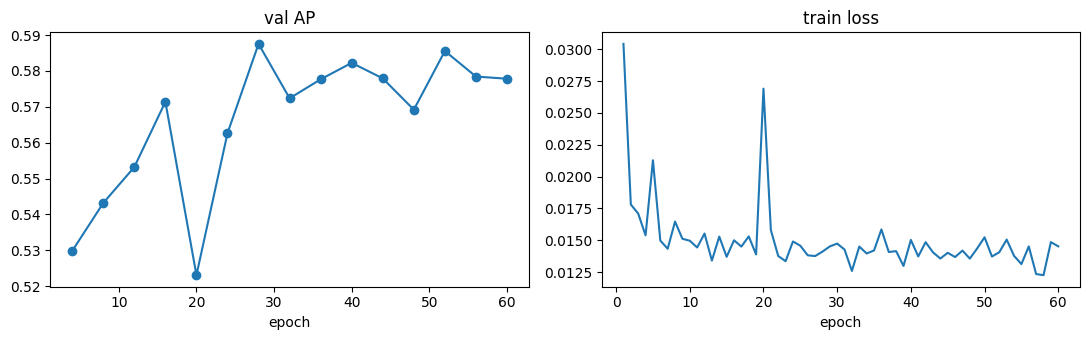

In [22]:
# 학습 곡선
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
hv = gine_hist.dropna(subset=['AP']); ax[0].plot(hv['epoch'], hv['AP'], marker='o'); ax[1].plot(gine_hist['epoch'], gine_hist['train_loss'])
ax[0].set_title('val AP'); ax[1].set_title('train loss'); ax[0].set_xlabel('epoch'); ax[1].set_xlabel('epoch')
plt.tight_layout(); plt.savefig(OUT_DIR / 'curves.png', dpi=120); plt.show()

## 7. 테스트 — 구간 전체

In [23]:
# 테스트 전 정리 — LightGBM 부스터가 학습 Dataset(bin) 을 붙들고 있고, 학습 행 인덱스도 테스트엔 필요 없다
for n in ['train_rows', 'train_mask', 'lgb_model', 'xgb_model', 'X_val', 'y_train']:
    globals().pop(n, None)
store.rows.pop('train', None)
gc.collect(); torch.cuda.empty_cache(); B.trim('(테스트 전 정리 후)')

RSS 11.9 GB (테스트 전 정리 후)


In [24]:
gine_score = B.test_gnn('gine', store, cfg, test_df, OUT_DIR, DEVICE, edge_updates=False, results=results)

RSS 6.0 GB 
[12:36:41] 그래프 to 168,490,912 + rev_to 168,490,912 간선 (정렬됨)  53s
RSS 14.2 GB 
gine (137분) {'AP': 0.5834, 'F1': 0.6434, 'precision': 0.7638, 'recall': 0.5557, 'threshold': 0.51, 'recall_at_1pct': 0.7953, 'unmatched_recall_at_1pct': 0.5095, 'ECE': 0.0014, 'F1_at_0.5': 0.643}


# 결과 — 저장된 점수 파일만으로 돌아간다
커널을 새로 켰으면 **0 절(설정 셀 3개)까지만** 돌리고 바로 여기부터. 재료는 `results/<DATASET>/<RUN_NAME>/`
- `{model}_test_scores.parquet` (edge_id, y, score) — 7 절·4 절에서 저장
- `results.json` — 검증/테스트 지표 (`results` dict 복구용)
- dst 와 수신자 in-degree 만 DuckDB 에서 다시 읽는다 (1~2 분)

운영점(컷)은 두 종류: **예산 컷** `r@b%` = 테스트 전체 상위 b% 를 알림으로 (0.05 / 0.1 / 0.5 / 1 / 2 / 5 / 10 % / all),
**argmax** = 확률 0.5 (논문 F1 운영점, Multi-GNN 부록 Table 13 의 패턴별 recall 과 같은 기준). 0.1% ≈ 양성 수 규모 ≈ argmax 와 비슷한 알림 수.

## 8. 준비 — 점수 · 라벨 · in-degree

In [25]:
import importlib; importlib.reload(B)
MODELS = [n for n in ['lightgbm', 'xgboost', 'gine'] if (OUT_DIR / f'{n}_test_scores.parquet').exists()]
scores = {n: B.load_scores(OUT_DIR / f'{n}_test_scores.parquet') for n in MODELS}
if 'test_df' not in globals() or 'in_degree' not in globals():
    con = L.connect(threads=8, memory='12GB')
    test_df = B.test_full(con, cfg.test_window); in_degree = B.recipient_indegree(con, cfg); con.close()
for n in MODELS:
    assert (scores[n]['edge_id'].to_numpy() == test_df['edge_id'].to_numpy()).all(), f'{n} 점수와 라벨 순서 불일치'
if 'results' not in globals() or not results:
    results = json.load(open(OUT_DIR / 'results.json'))['results']
print(MODELS, '| 테스트 간선', f"{len(test_df):,}", '| 양성', f"{int(test_df.y.sum()):,}", '| 컷', list(B.cut_thresholds(scores[MODELS[0]]['score'].to_numpy())))

['lightgbm', 'xgboost', 'gine'] | 테스트 간선 26,808,230 | 양성 34,460 | 컷 ['r@0.05%', 'r@0.1%', 'r@0.5%', 'r@1%', 'r@2%', 'r@5%', 'r@10%', 'all', 'argmax']


## 9. 운영점별 precision / recall
같은 점수를 컷만 바꿔 가며 본다. 예산을 줄이면 precision 이 오르고 recall 이 떨어지는 그 교환을 한 표에.

In [26]:
# 컷마다 임계값 · 알림 수 · TP/FP/FN · precision · recall (모델별). 'all' = 전부 알림 (precision = 양성 비율)
cut_df = pd.concat([B.cut_table(scores[n]).assign(model=n) for n in MODELS])
cut_df.to_csv(OUT_DIR / 'analysis_cuts.csv', encoding='utf-8-sig')
cut_df[cut_df.model == 'gine']

,threshold,alerts,TP,FP,FN,TN,precision,recall,model
cut,,,,,,,,,
r@0.05%,0.9593,13405,12125,1280,22335,26772490,0.9045,0.3519,gine
r@0.1%,0.4144,26809,19595,7214,14865,26766556,0.7309,0.5686,gine
r@0.5%,0.1404,170678,25090,145588,9370,26628182,0.1470,0.7281,gine
r@1%,0.0382,268083,27406,240677,7054,26533093,0.1022,0.7953,gine
r@2%,0.0109,536165,29766,506399,4694,26267371,0.0555,0.8638,gine
r@5%,0.0051,1340412,31362,1309050,3098,25464720,0.0234,0.9101,gine
r@10%,0.0032,2680824,33400,2647424,1060,24126346,0.0125,0.9692,gine
all,0.0000,26808230,34460,26773770,0,0,0.0013,1.0000,gine
argmax,0.5000,25229,19191,6038,15269,26767732,0.7607,0.5569,gine


In [27]:
# 모델 나란히 — 컷별 recall / precision
cut_df.reset_index().pivot(index='cut', columns='model', values=['recall', 'precision']).loc[cut_df.index.unique()]

recall                  precision                 
model      gine lightgbm xgboost      gine lightgbm xgboost
cut                                                        
r@0.05%  0.3519   0.3710  0.3741    0.9045   0.9537  0.9616
r@0.1%   0.5686   0.5899  0.5929    0.7309   0.7583  0.7621
r@0.5%   0.7281   0.7246  0.7232    0.1470   0.1863  0.1859
r@1%     0.7953   0.8129  0.8107    0.1022   0.1045  0.1042
r@2%     0.8638   0.8772  0.8699    0.0555   0.0564  0.0559
r@5%     0.9101   0.9209  0.9155    0.0234   0.0237  0.0235
r@10%    0.9692   0.9770  0.9726    0.0125   0.0126  0.0125
all      1.0000   1.0000  1.0000    0.0013   0.0013  0.0013
argmax   0.5569   0.6075  0.6035    0.7607   0.6714  0.7075

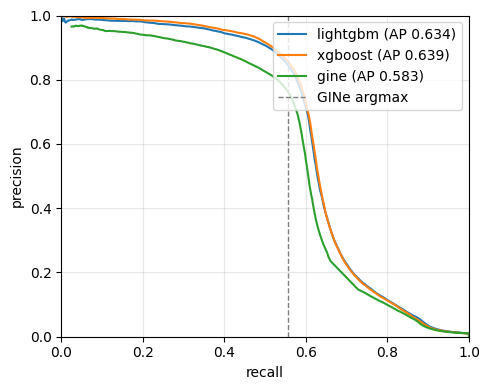

In [28]:
# PR 곡선 — 컷을 연속으로 훑은 것. AP = 곡선 아래 면적. 세로선 = GINe argmax 운영점
B.plot_pr(scores, path=OUT_DIR / 'pr_curve.png', mark=(cut_df.loc['argmax'].query("model == 'gine'")['recall'].iloc[0], 'GINe argmax'))

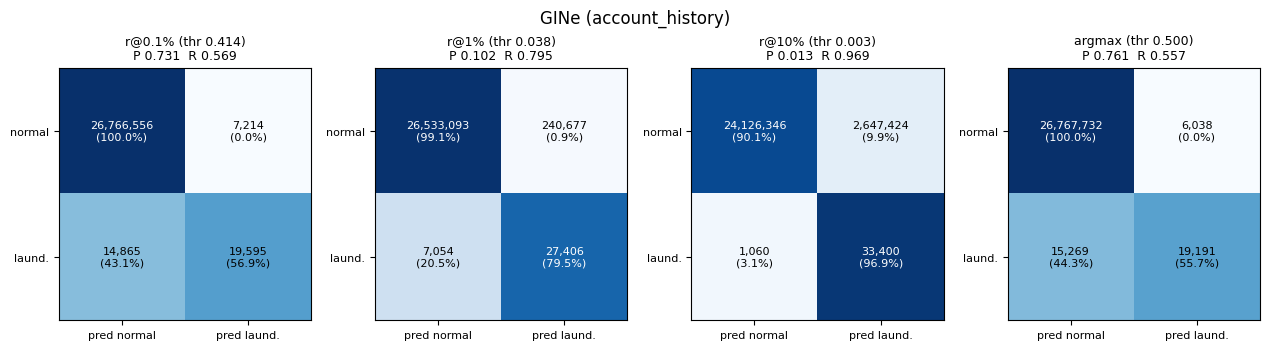

In [29]:
# 혼동행렬 — GINe, 컷 4개 나란히. 색 = 행 비율 (세탁 행 오른쪽 칸 = recall), 숫자 = 건수
B.plot_confusion_grid(scores['gine'], cuts=('r@0.1%', 'r@1%', 'r@10%', 'argmax'), title=f'GINe ({RUN_NAME})', path=OUT_DIR / 'confusion_cuts.png')

## 10. 패턴별 — 어느 패턴을 어느 컷에서 놓치나
패턴 안의 거래는 모두 양성이라 recall 만 본다. 예산을 줄일 때 먼저 떨어지는 패턴이 "모델이 덜 확신하는" 패턴.

In [30]:
# 패턴 × 컷 recall (모델별 저장, GINe 표시). 'recall' 열 = 1% (01 과 호환), mean_score = 그 패턴 양성의 평균 점수
pattern_df = pd.concat([B.pattern_recall(scores[n]).assign(model=n) for n in MODELS])
pattern_df.to_csv(OUT_DIR / 'analysis_pattern.csv', encoding='utf-8-sig')
CUT_COLS = [c for c in pattern_df.columns if c.startswith('r@') or c in ('all', 'argmax')]
pattern_df[pattern_df.model == 'gine'][['n'] + CUT_COLS + ['mean_score']]

,n,r@0.05%,r@0.1%,r@0.5%,r@1%,r@2%,r@5%,r@10%,all,argmax,mean_score
pattern_type,,,,,,,,,,,
FAN-OUT,2131,0.7344,0.9559,0.9897,0.9981,1.0000,1.0000,1.0000,1.0,0.9470,0.9205
FAN-IN,1922,0.6223,0.9313,0.9781,0.9964,0.9995,1.0000,1.0000,1.0,0.9116,0.8828
GATHER-SCATTER,3785,0.7022,0.9474,0.9852,0.9979,0.9997,0.9997,0.9997,1.0,0.9358,0.9098
SCATTER-GATHER,3891,0.6613,0.9507,0.9892,0.9985,1.0000,1.0000,1.0000,1.0,0.9383,0.9074
CYCLE,1853,0.5138,0.9298,0.9876,0.9978,0.9989,1.0000,1.0000,1.0,0.9147,0.8704
RANDOM,1335,0.4959,0.9213,0.9790,0.9970,0.9993,0.9993,0.9993,1.0,0.9079,0.8625
BIPARTITE,1833,0.4888,0.8811,0.9716,0.9962,1.0000,1.0000,1.0000,1.0,0.8609,0.8273
STACK,3437,0.4713,0.9092,0.9799,0.9962,0.9985,0.9994,0.9997,1.0,0.8883,0.8478
UNMATCHED,14273,0.0002,0.0553,0.3669,0.5095,0.6718,0.7832,0.9259,1.0,0.0483,0.1061


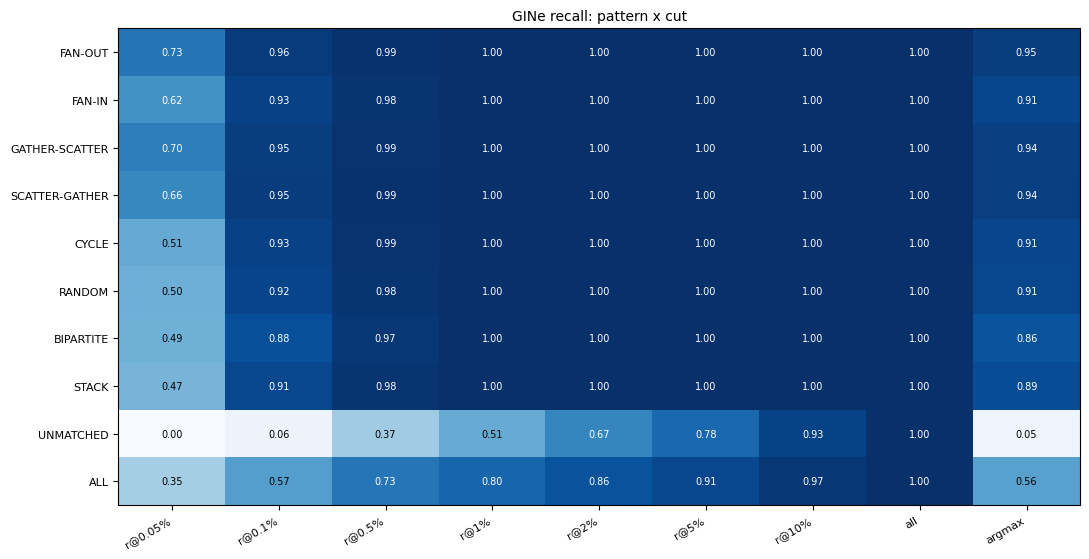

In [31]:
# 같은 표를 그림으로 — 행 = 패턴, 열 = 컷. 왼쪽(빡빡한 예산)에서 먼저 하얘지는 행이 약한 패턴
B.plot_heatmap(pattern_df[pattern_df.model == 'gine'][CUT_COLS], title='GINe recall: pattern x cut', path=OUT_DIR / 'pattern_x_cut.png')

In [32]:
# 놓친 세탁(FN) 의 구성 — 컷마다 FN 이 어느 패턴에서 나오나. FN% 가 pos_share 보다 크면 그 패턴을 유독 놓침
groups = dict(pattern=B.pattern_array(scores['gine']), degree_bin=B.degree_bin_of(test_df['dst'].to_numpy(), in_degree))
cb = B.confusion_breakdown(scores['gine'], groups)
for axis in groups:
    cb['fn'][axis].to_csv(OUT_DIR / f'analysis_fn_{axis}.csv', encoding='utf-8-sig'); cb['fp'][axis].to_csv(OUT_DIR / f'analysis_fp_{axis}.csv', encoding='utf-8-sig')
cb['fn']['pattern'][['pos_share'] + [c for c in cb['fn']['pattern'].columns if c.startswith('FN% ')]]

,pos_share,FN% r@0.05%,FN% r@0.1%,FN% r@0.5%,FN% r@1%,FN% r@2%,FN% r@5%,FN% r@10%,FN% all,FN% argmax
UNMATCHED,0.4142,0.6389,0.9070,0.9644,0.9925,0.9979,0.9987,0.9972,0.0,0.8896
SCATTER-GATHER,0.1129,0.0590,0.0129,0.0045,0.0009,0.0000,0.0000,0.0000,0.0,0.0157
GATHER-SCATTER,0.1098,0.0505,0.0134,0.0060,0.0011,0.0002,0.0003,0.0009,0.0,0.0159
STACK,0.0997,0.0814,0.0210,0.0074,0.0018,0.0011,0.0006,0.0009,0.0,0.0251
FAN-OUT,0.0618,0.0253,0.0063,0.0023,0.0006,0.0000,0.0000,0.0000,0.0,0.0074
FAN-IN,0.0558,0.0325,0.0089,0.0045,0.0010,0.0002,0.0000,0.0000,0.0,0.0111
CYCLE,0.0538,0.0403,0.0087,0.0025,0.0006,0.0004,0.0000,0.0000,0.0,0.0103
BIPARTITE,0.0532,0.0420,0.0147,0.0055,0.0010,0.0000,0.0000,0.0000,0.0,0.0167
RANDOM,0.0387,0.0301,0.0071,0.0030,0.0006,0.0002,0.0003,0.0009,0.0,0.0081


## 11. 수신자 in-degree 층화 (SALT-GNN 프로토콜)
허브(차수 큰 수신자) 쪽 거래가 약점인지. AP/F1 은 구간 안에서 따로 계산, recall/precision 은 전체 컷 임계값을 구간에 적용.

In [33]:
# 구간별 AP · F1 · 양성 비율 (모델별 저장, GINe 표시)
degree_df = pd.concat([B.degree_stratified(scores[n], test_df['dst'].to_numpy(), in_degree).assign(model=n) for n in MODELS])
degree_df.to_csv(OUT_DIR / 'analysis_degree.csv', encoding='utf-8-sig')
degree_df[degree_df.model == 'gine']

,n,n_pos,pos_rate,AP,F1,F1_at_0_5,recall_at_budget,recall_argmax,model
bin,,,,,,,,,
[1-4],232436,508,0.0022,0.5653,0.6623,0.6468,0.9783,0.7480,gine
[5-9],349131,2604,0.0075,0.7896,0.7953,0.7935,0.9620,0.7561,gine
[10-19],562520,4863,0.0086,0.5757,0.6376,0.6362,0.8674,0.5614,gine
[20-49],1102930,7132,0.0065,0.4812,0.5440,0.5432,0.7851,0.4499,gine
[50-99],893833,2493,0.0028,0.4595,0.5329,0.5313,0.6988,0.4011,gine
[100+],23667380,16860,0.0007,0.6081,0.6744,0.6739,0.7619,0.5874,gine


In [34]:
# 구간 × 컷 — recall 과 precision (GINe). 같은 임계값인데 구간마다 precision 이 다르면 알림이 그쪽에 몰리는 것
deg_cut = B.group_by_cut(scores['gine'], groups['degree_bin'])
order = [b for b in [f'[{lo}-{hi}]' if hi < 10**9 else f'[{lo}+]' for lo, hi in B.DEGREE_BINS] if b in deg_cut['recall'].index]
deg_cut['recall'].loc[order].to_csv(OUT_DIR / 'analysis_degree_x_cut_recall.csv', encoding='utf-8-sig')
deg_cut['precision'].loc[order].to_csv(OUT_DIR / 'analysis_degree_x_cut_precision.csv', encoding='utf-8-sig')
display(deg_cut['recall'].loc[order]); deg_cut['precision'].loc[order]

,r@0.05%,r@0.1%,r@0.5%,r@1%,r@2%,r@5%,r@10%,all,argmax,n_pos
[1-4],0.3720,0.7657,0.9173,0.9783,0.9980,1.0000,1.0000,1.0,0.7480,508
[5-9],0.4578,0.7715,0.9213,0.9620,0.9965,0.9973,0.9977,1.0,0.7561,2604
[10-19],0.3041,0.5764,0.7835,0.8674,0.9835,0.9924,0.9944,1.0,0.5614,4863
[20-49],0.2433,0.4658,0.6737,0.7851,0.9335,0.9821,0.9907,1.0,0.4499,7132
[50-99],0.2555,0.4091,0.5776,0.6988,0.7730,0.8516,0.9314,1.0,0.4011,2493
[100+],0.4088,0.5962,0.7218,0.7619,0.7886,0.8484,0.9531,1.0,0.5874,16860


,r@0.05%,r@0.1%,r@0.5%,r@1%,r@2%,r@5%,r@10%,all,argmax,n_pos
[1-4],0.6019,0.5679,0.2350,0.1785,0.1353,0.1102,0.1006,0.0022,0.5697,508
[5-9],0.9393,0.8143,0.1844,0.1354,0.0980,0.0935,0.0913,0.0075,0.8347,2604
[10-19],0.8942,0.6981,0.1049,0.0759,0.0460,0.0431,0.0423,0.0086,0.7341,4863
[20-49],0.8994,0.6445,0.1130,0.0744,0.0373,0.0275,0.0261,0.0065,0.6852,7132
[50-99],0.9179,0.7539,0.1476,0.1029,0.0542,0.0235,0.0131,0.0028,0.7868,2493
[100+],0.9136,0.7653,0.1813,0.1297,0.0709,0.0168,0.0077,0.0007,0.7903,16860


In [35]:
# 잘못 잡은 정상(FP) 이 어느 차수 구간에 몰리나 — FP% 가 neg_share 보다 크면 그 구간에 알림이 과함
cb['fp']['degree_bin'][['neg_share'] + [c for c in cb['fp']['degree_bin'].columns if c.startswith('FP% ')]]

,neg_share,FP% r@0.05%,FP% r@0.1%,FP% r@0.5%,FP% r@1%,FP% r@2%,FP% r@5%,FP% r@10%,FP% all,FP% argmax
[100+],0.8833,0.5094,0.4274,0.3774,0.3582,0.3442,0.6394,0.7816,0.8833,0.4351
[20-49],0.0409,0.1516,0.2540,0.2589,0.2894,0.3397,0.1889,0.0995,0.0409,0.2441
[50-99],0.0333,0.0445,0.0462,0.0571,0.0631,0.0665,0.0674,0.0660,0.0333,0.0449
[10-19],0.0208,0.1367,0.1680,0.2232,0.2133,0.1960,0.0819,0.0413,0.0208,0.1638
[5-9],0.0129,0.0602,0.0635,0.0729,0.0665,0.0472,0.0192,0.0098,0.0129,0.0646
[1-4],0.0087,0.0977,0.0410,0.0104,0.0095,0.0064,0.0031,0.0017,0.0087,0.0475


## 12. 앞 단계 (PREV_RUN) 와 비교
앞 단계 결과 폴더의 `analysis_*.csv` 와 비교. 01 은 모델 이름이 `gine_basic`, 02 부터는 `gine`.

In [36]:
# 패턴별 recall — 1% 와 argmax 두 컷에서 앞 단계 GINe vs 이번 GINe
PREV_GNN = 'gine_basic' if PREV_RUN == 'basic_features' else 'gine'
prev_path = Path.cwd() / 'results' / cfg.dataset / PREV_RUN / 'analysis_pattern.csv'
if prev_path.exists():
    prev = pd.read_csv(prev_path, index_col=0); prev = prev[prev.model == PREV_GNN]; cur = pattern_df[pattern_df.model == 'gine']
    cmp = pd.DataFrame({f'{PREV_RUN} r@1%': prev['recall'], f'{RUN_NAME} r@1%': cur['recall']})
    cmp['diff r@1%'] = cmp.iloc[:, 1] - cmp.iloc[:, 0]
    if 'argmax' in prev.columns:
        cmp[f'{PREV_RUN} argmax'] = prev['argmax']; cmp[f'{RUN_NAME} argmax'] = cur['argmax']; cmp['diff argmax'] = cur['argmax'] - prev['argmax']
    display(cmp.loc[[p for p in B.PATTERN_ORDER + ['ALL'] if p in cmp.index]].round(4))
else:
    print('앞 단계 분석표 없음 —', prev_path)

,account_activity r@1%,account_history r@1%,diff r@1%,account_activity argmax,account_history argmax,diff argmax
pattern_type,,,,,,
FAN-OUT,0.9962,0.9981,0.0019,0.9625,0.9470,-0.0155
FAN-IN,0.9964,0.9964,0.0000,0.9459,0.9116,-0.0343
GATHER-SCATTER,0.9968,0.9979,0.0011,0.9585,0.9358,-0.0227
SCATTER-GATHER,0.9961,0.9985,0.0024,0.9630,0.9383,-0.0247
CYCLE,0.9897,0.9978,0.0081,0.9174,0.9147,-0.0027
RANDOM,0.9918,0.9970,0.0052,0.9139,0.9079,-0.0060
BIPARTITE,0.9929,0.9962,0.0033,0.8783,0.8609,-0.0174
STACK,0.9904,0.9962,0.0058,0.9078,0.8883,-0.0195
UNMATCHED,0.4312,0.5095,0.0783,0.0125,0.0483,0.0358


In [37]:
# 수신 계좌 degree 구간별 AP — 허브 구간이 달라졌나
prev_path = Path.cwd() / 'results' / cfg.dataset / PREV_RUN / 'analysis_degree.csv'
if prev_path.exists():
    prev_d = pd.read_csv(prev_path, index_col=0); prev_d = prev_d[prev_d.model == PREV_GNN]; cur_d = degree_df[degree_df.model == 'gine']
    display(pd.DataFrame({f'{PREV_RUN} AP': prev_d['AP'], f'{RUN_NAME} AP': cur_d['AP'], 'diff': cur_d['AP'] - prev_d['AP'],
                          f'{PREV_RUN} F1': prev_d['F1'], f'{RUN_NAME} F1': cur_d['F1'], 'n_pos': cur_d['n_pos']}).round(4))
else:
    print('앞 단계 분석표 없음:', prev_path)

,account_activity AP,account_history AP,diff,account_activity F1,account_history F1,n_pos
bin,,,,,,
[1-4],0.6153,0.5653,-0.0500,0.6661,0.6623,508
[5-9],0.7878,0.7896,0.0018,0.7754,0.7953,2604
[10-19],0.5388,0.5757,0.0369,0.6030,0.6376,4863
[20-49],0.4456,0.4812,0.0356,0.5318,0.5440,7132
[50-99],0.4466,0.4595,0.0129,0.5369,0.5329,2493
[100+],0.5726,0.6081,0.0355,0.6492,0.6744,16860


## 13. 비교표 + 저장

In [38]:
compare_df = B.save_results(OUT_DIR, cfg, results, features=dict(tree=TREE_FEATURES, gnn=GNN_EDGE_FEATURES))
compare_df

AP      F1  F1_at_0.5  precision  recall  recall_at_1pct  \
model    split                                                                 
lightgbm val    0.6460  0.6847     0.6551     0.8541  0.5714          0.8081   
         test   0.6341  0.6722     0.6379     0.8178  0.5706          0.8129   
xgboost  val    0.6505  0.6871     0.6663     0.8513  0.5760          0.8056   
         test   0.6393  0.6767     0.6514     0.8372  0.5679          0.8107   
gine     val    0.5875  0.6453     0.6429     0.7827  0.5490          0.7961   
         test   0.5834  0.6434     0.6430     0.7638  0.5557          0.7953   

                unmatched_recall_at_1pct     ECE  train_sec  
model    split                                               
lightgbm val                      0.5278  0.0026       2258  
         test                     0.5491  0.0027       2258  
xgboost  val                      0.5217  0.0025       2470  
         test                     0.5439  0.0025       2470  
gine     val                      0.5015  0.0013      14011  
         test                     0.5095  0.0014      14011

In [39]:
# 앞 단계 전체 지표와 나란히
prev_c = pd.read_csv(Path.cwd() / 'results' / cfg.dataset / PREV_RUN / 'compare.csv', index_col=[0, 1])
pd.concat([prev_c.assign(run=PREV_RUN), compare_df.assign(run=RUN_NAME)]).reset_index().set_index(['run', 'model', 'split'])[['AP', 'F1', 'F1_at_0.5', 'recall_at_1pct', 'unmatched_recall_at_1pct']]

AP      F1  F1_at_0.5  recall_at_1pct  \
run              model    split                                              
account_activity lightgbm val    0.5137  0.5543     0.5273          0.7707   
                          test   0.5241  0.5636     0.5390          0.7654   
                 xgboost  val    0.5180  0.5635     0.5067          0.7620   
                          test   0.5251  0.5666     0.5232          0.7621   
                 gine     val    0.5613  0.6241     0.6207          0.7588   
                          test   0.5487  0.6190     0.6069          0.7610   
account_history  lightgbm val    0.6460  0.6847     0.6551          0.8081   
                          test   0.6341  0.6722     0.6379          0.8129   
                 xgboost  val    0.6505  0.6871     0.6663          0.8056   
                          test   0.6393  0.6767     0.6514          0.8107   
                 gine     val    0.5875  0.6453     0.6429          0.7961   
                          test   0.5834  0.6434     0.6430          0.7953   

                                 unmatched_recall_at_1pct  
run              model    split                            
account_activity lightgbm val                      0.4463  
                          test                     0.4533  
                 xgboost  val                      0.4219  
                          test                     0.4396  
                 gine     val                      0.4156  
                          test                     0.4312  
account_history  lightgbm val                      0.5278  
                          test                     0.5491  
                 xgboost  val                      0.5217  
                          test                     0.5439  
                 gine     val                      0.5015  
                          test                     0.5095

In [40]:
sorted(p.name for p in OUT_DIR.iterdir())   # 이 폴더가 report.md 의 재료

['analysis_cuts.csv',
 'analysis_degree.csv',
 'analysis_degree_x_cut_precision.csv',
 'analysis_degree_x_cut_recall.csv',
 'analysis_fn_degree_bin.csv',
 'analysis_fn_pattern.csv',
 'analysis_fp_degree_bin.csv',
 'analysis_fp_pattern.csv',
 'analysis_pattern.csv',
 'compare.csv',
 'confusion_cuts.png',
 'curves.png',
 'gine.pt',
 'gine_history.csv',
 'gine_test_scores.parquet',
 'lightgbm_test_scores.parquet',
 'pattern_x_cut.png',
 'pr_curve.png',
 'results.json',
 'xgboost_test_scores.parquet']

## 14. 다음
- amount_seen 조건 (`USE_AMOUNT_SEEN = True`) 한 번 더 — v10 최강 무패턴 신호의 효과와 일반화 위험을 분리해서 기록
- 05: GFP 모티프 (2홉 경로·사이클 수, snapml) → CYCLE, SCATTER-GATHER. 06 결과에 따라 03 또는 06 위에
- 1단계 정리 → 2단계 모델 비교 (HI-Small, timestamp 를 시간대로 교체한 설정)